<a href="https://colab.research.google.com/github/emonrol/FAQ/blob/master/week03/gradient_descent_training0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Introduction to Gradient Descent Training


In this notebook, we implement the gradient descent learning algorithm for a linear neuron.

Unlike the Rosenblatt perceptron, where weights are updated only when the model makes a mistake, gradient descent updates the weights **at every step** based on the value of the error.

The goal is to understand that training a neural model can be formulated as an optimization problem:  
we iteratively minimize a loss function (Mean Squared Error).

---

## Main Task – Stochastic Gradient Descent (SGD)

You are given a skeleton of the `gradient_descent` method.

**Complete the missing parts:**
- compute the predicted output (forward pass),
- calculate the error,
- update the weights and bias using the gradient update rule,
- compute the Mean Squared Error after each epoch.

---

### What You Should Observe

- The weights are updated gradually (not only when classification is wrong).
- The learning rate controls the size of the update step.
- Different learning rates may lead to slow convergence or divergence.
- The training process is iterative and depends on initialization.

---

## Additional Task – Batch Gradient Descent

You are given a skeleton of the `batch_gradient_descent` method.

**Complete the missing parts:**
- compute predictions for all samples,
- compute the vector of errors,
- update weights and bias using the batch gradient update rule.

In this case:
- the gradient is computed using the **entire dataset at once**,  
- the weights are updated **once per epoch**,  
- no update happens inside the inner loop over samples.

---

### Compare Both Approaches

After implementing both versions:

- Compare the convergence behaviour of SGD and batch gradient descent.
- Observe the smoothness of the error curve.
- Try different learning rates and compare stability.
- Which method converges faster?
- Which method is more stable?

---

### Think About It

- Why is batch gradient descent often impractical for very large datasets?

Each step would become really slow because it has to process all the dataset before updating the weights.

- Why do modern neural networks typically use mini-batch gradient descent instead?

Batching is still an improvement compared to the stochastic method because it approximates better the gradient using several samples at once. However, we have seen that for large datasets it becomes impractical. The solution is something intermediate getting the best of both worlds, speed and accuracy.


In [35]:
import numpy as np

def MSE(d, y):
    return np.mean((d - y)**2)

class LinearNeuron:
    def __init__(self, weights, bias) -> None:
        self.weights = np.array(weights, dtype=np.float64)
        self.bias = bias

    def internal_potential(self, inputs)  -> float:
        return inputs @ self.weights.T + self.bias

    def activation(self, xi): # identity
        return xi

    def forward(self, inputs) -> float:
        potential = self.internal_potential(inputs)
        return self.activation(potential)

    def gradient_descent(self, X, d, learning_rate=0.01, epochs=100):
        """
        Stochastic gradient descent  for linear neuron (MSE loss) – to be completed.
        """

        n_samples = len(X)
        training_errors = []

        for epoch in range(epochs):

            # 1) Shuffle data
            indices = np.random.permutation(n_samples)
            X = X[indices]
            d = d[indices]

            for inputs, true_output in zip(X, d):

                 # 2) Forward pass
                prediction = self.forward(inputs)

                # 3) Compute error (it's not sse)
                error = (-prediction  +true_output)

                # 4) Update weights
                self.weights += learning_rate*error*inputs

                # 5) Update bias
                self.bias += learning_rate*error

            # 6) Compute MSE for whole dataset (use the implemented MSE() function)
            predictions= self.forward(X)
            mse = MSE(d,predictions)
            training_errors.append(mse)
            print(f"Epoch {epoch+1}/{epochs} - MSE: {mse:.6f} weights: {self.weights} bias: {self.bias}")


        return training_errors


    def gradient_descent_batch(self, X, d, learning_rate=0.01, epochs=100):
        """
        Batch gradient descent for linear neuron (MSE loss).
        """
        n_samples = len(X)
        training_errors = []

        for epoch in range(epochs):

            # Forward pass for all samples
            predictions = self.forward(X)


            # Compute error vector
            errors = d-predictions

            # Update parameters
            self.weights += learning_rate*X.T.dot(errors)
            self.bias += learning_rate*np.sum(errors)

            # Compute MSE
            mse = MSE(d, predictions)
            training_errors.append(mse)

            print(f"[Batch] Epoch {epoch+1}/{epochs} - MSE: {mse:.6f} weights: {self.weights} bias: {self.bias}")

        return training_errors

    def __str__(self) -> str:
        return f"Perceptron(weights={self.weights}, bias={self.bias})"




### Running the example

- Train the linear neuron on the given dataset.
- Observe the training results:
  - final weight and bias,
  - predicted outputs,
  - overall Mean Squared Error (MSE).
- Experiment by modifying:
  - the variant of the training algorithm
  - the training data,
  - initial weights and bias,
  - learning rate,
  - number of epochs.



In [36]:
# Small editable dataset ... corresponds to y = 2x + 1

X = np.array([
    [-2.0],
    [-1.0],
    [ 0.0],
    [ 1.0],
    [ 2.0]
])

d = np.array([
    -3.0,   # for x = -2
    -1.0,   # for x = -1
     1.0,   # for x =  0
     3.0,   # for x =  1
     5.0    # for x =  2
])
X.shape, d.shape

((5, 1), (5,))

In [37]:
# Alternatively: random dataset
"""
X = np.random.randn(100, 2)
d = 2 * X[:, 0] + 3 * X[:, 1] + 1 + 0.8 * np.random.randn(100)
X.shape, d.shape
"""

'\nX = np.random.randn(100, 2)\nd = 2 * X[:, 0] + 3 * X[:, 1] + 1 + 0.8 * np.random.randn(100)\nX.shape, d.shape\n'

Before training:
Perceptron(weights=[-0.89806289], bias=0.30877959861720383)
Epoch 1/100 - MSE: 14.120507 weights: [-0.61604279] bias: 0.34186086433187746
Epoch 2/100 - MSE: 11.548344 weights: [-0.36208763] bias: 0.3759583511700743
Epoch 3/100 - MSE: 9.445483 weights: [-0.13219944] bias: 0.4059172082206945
Epoch 4/100 - MSE: 7.727758 weights: [0.07551885] bias: 0.4338703641695181
Epoch 5/100 - MSE: 6.327065 weights: [0.26245393] bias: 0.46247565137206775
Epoch 6/100 - MSE: 5.181556 weights: [0.43159006] bias: 0.48839803470280774
Epoch 7/100 - MSE: 4.246356 weights: [0.58401204] bias: 0.5138803264550255
Epoch 8/100 - MSE: 3.481003 weights: [0.72196589] bias: 0.5371165739502198
Epoch 9/100 - MSE: 2.855927 weights: [0.84626028] bias: 0.5598910427619629
Epoch 10/100 - MSE: 2.343625 weights: [0.95896565] bias: 0.5803332783964855
Epoch 11/100 - MSE: 1.926130 weights: [1.0598992] bias: 0.6018158490215473
Epoch 12/100 - MSE: 1.583461 weights: [1.15153135] bias: 0.6209712181945607
Epoch 13/100 

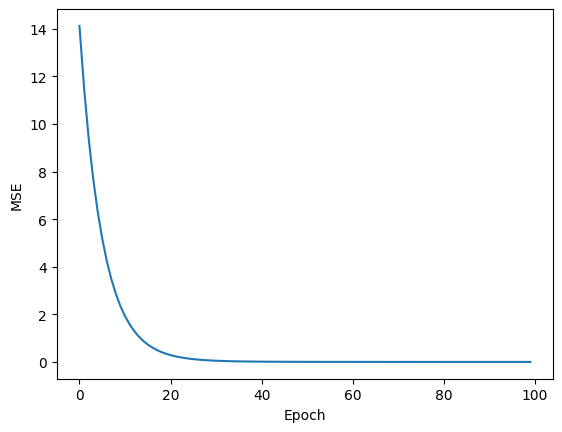


After training:
Perceptron(weights=[1.99990433], bias=0.9956576444370719)
Final MSE: 0.000019
    Input  Predicted  True
0  [-2.0]  -3.004151  -3.0
1  [-1.0]  -1.004247  -1.0
2   [0.0]   0.995658   1.0
3   [1.0]   2.995562   3.0
4   [2.0]   4.995466   5.0
[Batch] Epoch 1/100 - MSE: 9.115607 weights: [1.57387337] bias: -1.9568499742405303
[Batch] Epoch 2/100 - MSE: 9.106130 weights: [1.5742995] bias: -1.95537154925341
[Batch] Epoch 3/100 - MSE: 9.096663 weights: [1.5747252] bias: -1.9538938634787832
[Batch] Epoch 4/100 - MSE: 9.087206 weights: [1.57515047] bias: -1.9524169165470437
[Batch] Epoch 5/100 - MSE: 9.077760 weights: [1.57557532] bias: -1.9509407080887702
[Batch] Epoch 6/100 - MSE: 9.068324 weights: [1.57599975] bias: -1.9494652377347257
[Batch] Epoch 7/100 - MSE: 9.058898 weights: [1.57642375] bias: -1.9479905051158584
[Batch] Epoch 8/100 - MSE: 9.049482 weights: [1.57684732] bias: -1.9465165098633004
[Batch] Epoch 9/100 - MSE: 9.040076 weights: [1.57727048] bias: -1.94504325

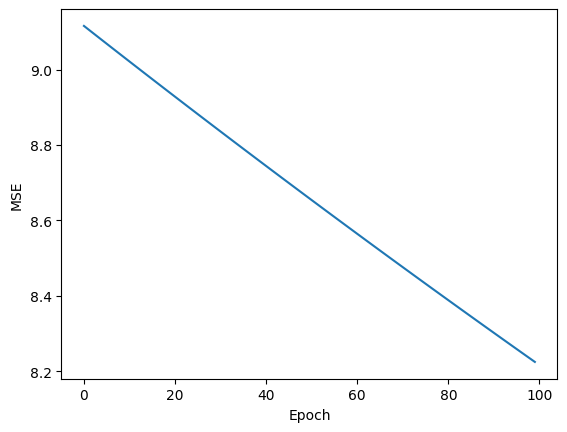


After training:
Perceptron(weights=[1.61405803], bias=-1.8140145370627019)
Final MSE: 8.225102
    Input  Predicted  True
0  [-2.0]  -5.042131  -3.0
1  [-1.0]  -3.428073  -1.0
2   [0.0]  -1.814015   1.0
3   [1.0]  -0.199957   3.0
4   [2.0]   1.414102   5.0


In [53]:
#model = LinearNeuron(weights=np.array([0.]), bias=0.0)
model = LinearNeuron(weights=np.random.randn(1), bias= np.random.randn())
print("Before training:")
print(model)

errors = model.gradient_descent(X, d, learning_rate=0.01, epochs=100)
#errors = model.gradient_descent_batch(X, d, learning_rate=0.0001, epochs=100)

import matplotlib.pyplot as plt
plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

print("\nAfter training:")
print(model)
print(f"Final MSE: {errors[-1]:f}")

# Compare the true and predicted outputs
import pandas as pd
df = pd.DataFrame(columns=['Input', 'Predicted', 'True'])
y = model.forward(X)
for inputs, true_output, predicted_output in zip(X, d, y):
    df.loc[len(df)] = {'Input': inputs, 'Predicted': predicted_output, 'True': true_output}
print(df)


model = LinearNeuron(weights=np.random.randn(1), bias= np.random.randn())
#errors = model.gradient_descent(X, d, learning_rate=0.01, epochs=100)
errors = model.gradient_descent_batch(X, d, learning_rate=0.0001, epochs=100)

import matplotlib.pyplot as plt
plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

print("\nAfter training:")
print(model)
print(f"Final MSE: {errors[-1]:f}")

# Compare the true and predicted outputs
import pandas as pd
df = pd.DataFrame(columns=['Input', 'Predicted', 'True'])
y = model.forward(X)
for inputs, true_output, predicted_output in zip(X, d, y):
    df.loc[len(df)] = {'Input': inputs, 'Predicted': predicted_output, 'True': true_output}
print(df)


At a glance, the winner is clearly using batching, it converges faster (because each epoch processes all the date before updating the weights versus the stochastic that only uses one sample and has more noise).

When we say "faster" we think in epochs, but in time, the stochastic method takes less time to execute due to the smaller operations it requires in detriment to stability and convergence.

Let's try for other learning rate values

Before training:
Perceptron(weights=[0.04488078], bias=-1.8429179028892184)
Epoch 1/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 2/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 3/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 4/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 5/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 6/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 7/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 8/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 9/10 - MSE: 0.000000 weights: [2.] bias: 1.0
Epoch 10/10 - MSE: 0.000000 weights: [2.] bias: 1.0


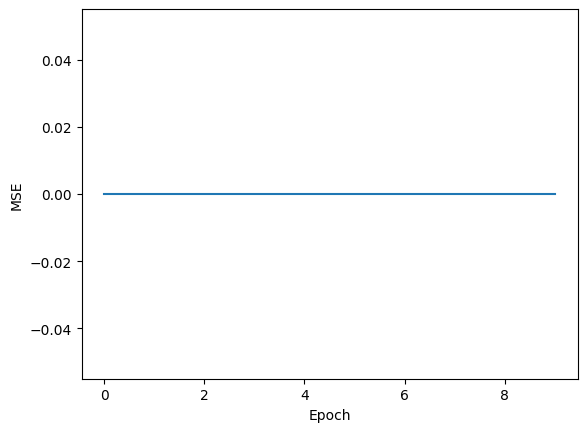


After training:
Perceptron(weights=[2.], bias=1.0)
Final MSE: 0.000000
[Batch] Epoch 1/100 - MSE: 12.978389 weights: [4.54359397] bias: 1.0
[Batch] Epoch 2/100 - MSE: 12.939741 weights: [-0.54359397] bias: 1.0
[Batch] Epoch 3/100 - MSE: 12.939741 weights: [4.54359397] bias: 1.0
[Batch] Epoch 4/100 - MSE: 12.939741 weights: [-0.54359397] bias: 1.0
[Batch] Epoch 5/100 - MSE: 12.939741 weights: [4.54359397] bias: 1.0
[Batch] Epoch 6/100 - MSE: 12.939741 weights: [-0.54359397] bias: 1.0
[Batch] Epoch 7/100 - MSE: 12.939741 weights: [4.54359397] bias: 1.0
[Batch] Epoch 8/100 - MSE: 12.939741 weights: [-0.54359397] bias: 1.0
[Batch] Epoch 9/100 - MSE: 12.939741 weights: [4.54359397] bias: 1.0
[Batch] Epoch 10/100 - MSE: 12.939741 weights: [-0.54359397] bias: 1.0
[Batch] Epoch 11/100 - MSE: 12.939741 weights: [4.54359397] bias: 1.0
[Batch] Epoch 12/100 - MSE: 12.939741 weights: [-0.54359397] bias: 1.0
[Batch] Epoch 13/100 - MSE: 12.939741 weights: [4.54359397] bias: 1.0
[Batch] Epoch 14/100 

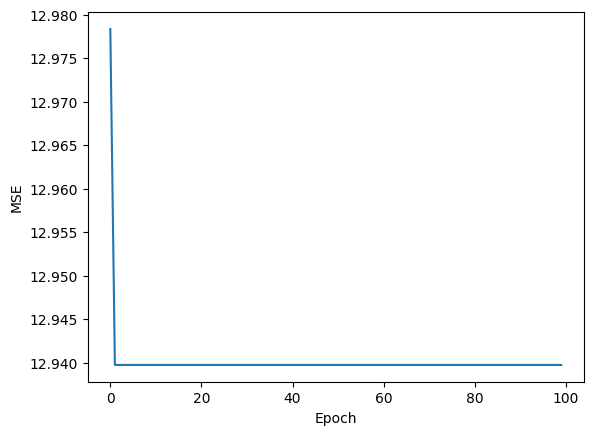


After training:
Perceptron(weights=[-0.54359397], bias=1.0)
Final MSE: 12.939741


,Input,Predicted,True
0,[-2.0],2.087188,-3.0
1,[-1.0],1.543594,-1.0
2,[0.0],1.000000,1.0
3,[1.0],0.456406,3.0
4,[2.0],-0.087188,5.0


In [51]:
#model = LinearNeuron(weights=np.array([0.]), bias=0.0)
model = LinearNeuron(weights=np.random.randn(1), bias= np.random.randn())
print("Before training:")
print(model)

errors = model.gradient_descent(X, d, learning_rate=0.5, epochs=10)
#errors = model.gradient_descent_batch(X, d, learning_rate=0.0001, epochs=100)

import matplotlib.pyplot as plt
plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

print("\nAfter training:")
print(model)
print(f"Final MSE: {errors[-1]:f}")

# Compare the true and predicted outputs
import pandas as pd
df = pd.DataFrame(columns=['Input', 'Predicted', 'True'])
y = model.forward(X)
for inputs, true_output, predicted_output in zip(X, d, y):
    df.loc[len(df)] = {'Input': inputs, 'Predicted': predicted_output, 'True': true_output}
df


model = LinearNeuron(weights=np.random.randn(1), bias= np.random.randn())
#errors = model.gradient_descent(X, d, learning_rate=0.01, epochs=100)
errors = model.gradient_descent_batch(X, d, learning_rate=0.2, epochs=100)

import matplotlib.pyplot as plt
plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

print("\nAfter training:")
print(model)
print(f"Final MSE: {errors[-1]:f}")

# Compare the true and predicted outputs
import pandas as pd
df = pd.DataFrame(columns=['Input', 'Predicted', 'True'])
y = model.forward(X)
for inputs, true_output, predicted_output in zip(X, d, y):
    df.loc[len(df)] = {'Input': inputs, 'Predicted': predicted_output, 'True': true_output}
df


We see how if we increase the learning rate, it converges faster but the stochastic remains stagnant. Let's add an outlier. As shown, it doesn't eliminate the mse error completely

Epoch 1/100 - MSE: 629.342848 weights: [1.93839803] bias: -0.1622963441584509
Epoch 2/100 - MSE: 231.416022 weights: [3.15465892] bias: -0.09539834575357563
Epoch 3/100 - MSE: 90.634416 weights: [3.88136586] bias: -0.052202295170570755
Epoch 4/100 - MSE: 41.323333 weights: [4.31362153] bias: -0.025668931436067813
Epoch 5/100 - MSE: 24.347742 weights: [4.56690541] bias: -0.00614187193535324
Epoch 6/100 - MSE: 18.423456 weights: [4.71781835] bias: 0.008250562254182386
Epoch 7/100 - MSE: 16.278852 weights: [4.8141678] bias: 0.019387586014426708
Epoch 8/100 - MSE: 15.640247 weights: [4.86707929] bias: 0.028197102567393183
Epoch 9/100 - MSE: 15.468966 weights: [4.89141317] bias: 0.03576678125271759
Epoch 10/100 - MSE: 15.404007 weights: [4.90487046] bias: 0.04269961375900627
Epoch 11/100 - MSE: 15.365117 weights: [4.91833045] bias: 0.0496408649886111
Epoch 12/100 - MSE: 15.353101 weights: [4.93245157] bias: 0.05656051219442377
Epoch 13/100 - MSE: 15.354431 weights: [4.94069696] bias: 0.0631

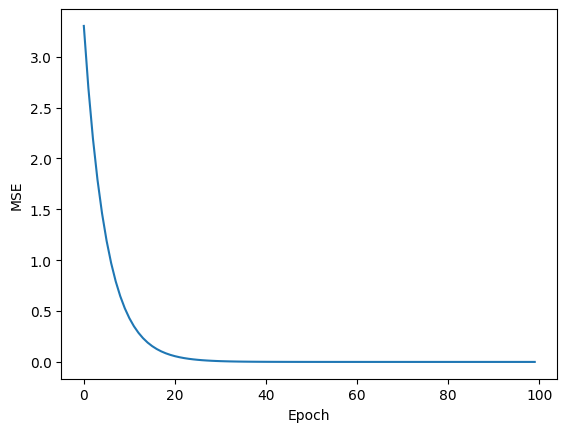

In [44]:
X_out = np.vstack([X, [[20.0]]])
d_out = np.append(d, [100.0])

model = LinearNeuron(weights=np.random.randn(1), bias=np.random.randn())
errors_out = model.gradient_descent(X_out, d_out, learning_rate=0.001, epochs=100)

plt.plot(errors)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.show()

We compare the performance as well if we normalise the data. Results difer but there is not a clear advantage. This may be due to the fact that the original data have similar values and scaling doesn't vary much the values.

[[-1. ]
 [-0.5]
 [ 0. ]
 [ 0.5]
 [ 1. ]]
[[-2.]
 [-1.]
 [ 0.]
 [ 1.]
 [ 2.]]
Epoch 1/100 - MSE: 3.530514 weights: [0.86122183] bias: 0.032073284919495265
Epoch 2/100 - MSE: 2.959716 weights: [0.97221873] bias: 0.07964801738458568
Epoch 3/100 - MSE: 2.488040 weights: [1.07160798] bias: 0.125805229372164
Epoch 4/100 - MSE: 2.095244 weights: [1.161951] bias: 0.16898125577213857
Epoch 5/100 - MSE: 1.767637 weights: [1.2441699] bias: 0.20938079809852858
Epoch 6/100 - MSE: 1.495423 weights: [1.31804219] bias: 0.24814221797618038
Epoch 7/100 - MSE: 1.269208 weights: [1.3839772] bias: 0.28568903055037886
Epoch 8/100 - MSE: 1.078863 weights: [1.44450492] bias: 0.32050507417751734
Epoch 9/100 - MSE: 0.920609 weights: [1.4979913] bias: 0.3545674467208888
Epoch 10/100 - MSE: 0.787368 weights: [1.54654235] bias: 0.3867134711161802
Epoch 11/100 - MSE: 0.675166 weights: [1.59038593] bias: 0.4172491729204854
Epoch 12/100 - MSE: 0.580142 weights: [1.63043822] bias: 0.44593337289460594
Epoch 13/100 - MS

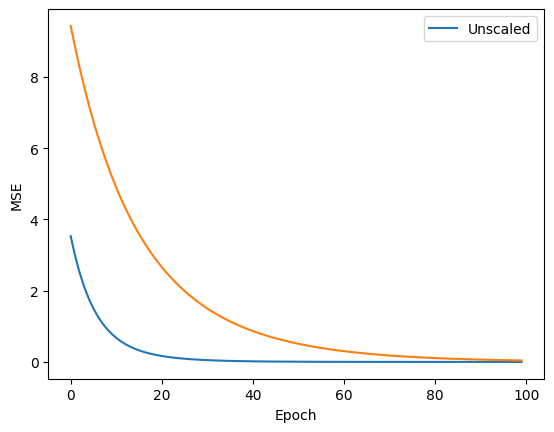

In [47]:
X_scaled = X / np.max(np.abs(X))
print(X_scaled)
print(X)

model_uns = LinearNeuron(weights=np.random.randn(1), bias=np.random.randn())
errors_uns = model_uns.gradient_descent(X, d, learning_rate=0.01, epochs=100)

model_scaled = LinearNeuron(weights=np.random.randn(1), bias=np.random.randn())
errors_scaled = model_scaled.gradient_descent(X_scaled, d, learning_rate=0.01, epochs=100)

plt.figure()
plt.plot(errors_uns, label="Unscaled")
plt.plot(errors_scaled)
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.legend()
plt.show()

# Exercise

In [ ]:
We estimate the number of hours of sport performed during the day.
The inputs are whether the day is sunny, whether the person partied the night before, and the number of hours studied during the day.
The numbers were generated with AI and were added some noise